# 05 — Final evaluation (FD001)

Every model scored in one place, on the 100 validation points and on the 100 test engines. Errors are split into **early** points (true RUL > 125, far from failure) and **late** points (true RUL ≤ 125, close to failure). Points are grouped by their *true* RUL, never by the prediction. 125 is a convention borrowed from C-MAPSS papers, not a tuned value.

The test set is scored only here, once. No model is changed after these numbers.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from load_data import load_test_rul
from evaluation import CUTOFFS, mae, rmse

MODELS = ["ols_v1", "elastic_net_v2", "random_forest", "gradient_boosting"]
THRESHOLD = 125

## 1. Load the answers and the predictions

In [2]:
val = (CUTOFFS
       .merge(pd.read_csv("../results/val_predictions_linear.csv"), on=["engine_id", "cycle"])
       .merge(pd.read_csv("../results/val_predictions_trees.csv"), on=["engine_id", "cycle"]))
test = (load_test_rul()
        .merge(pd.read_csv("../results/test_predictions_linear.csv"), on="engine_id")
        .merge(pd.read_csv("../results/test_predictions_trees.csv"), on="engine_id"))

print("validation:", val.shape)
print("test:      ", test.shape)
for name, d in [("validation", val), ("test", test)]:
    assert len(d) == 100, name
    assert {"rul", *MODELS} <= set(d.columns), name
    assert d[["rul", *MODELS]].notna().all().all(), name

validation: (100, 7)
test:       (100, 6)


## 2. Score by early / late band

In [3]:
def score_by_band(y_true, y_pred):
    """MAE and RMSE for early (true RUL > THRESHOLD) and late (true RUL <= THRESHOLD) points."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    early = y_true > THRESHOLD
    late = ~early
    out = {}
    for name, mask in [("early", early), ("late", late)]:
        n = int(mask.sum())
        if n == 0:
            out[name] = {"n": 0, "mae": np.nan, "rmse": np.nan}
        else:
            out[name] = {"n": n, "mae": mae(y_true[mask], y_pred[mask]),
                         "rmse": rmse(y_true[mask], y_pred[mask])}
    return out

## 3. Final table

In [4]:
rows = []
for set_name, d in [("validation", val), ("test", test)]:
    y_true = d["rul"].to_numpy()
    for model in MODELS:
        y_pred = d[model].to_numpy()
        bands = score_by_band(y_true, y_pred)
        late = y_true <= THRESHOLD
        late_over_pct = 100 * np.mean(y_pred[late] > y_true[late]) if late.any() else np.nan
        rows.append({
            "set": set_name, "model": model, "n": len(d),
            "mae": mae(y_true, y_pred), "rmse": rmse(y_true, y_pred),
            "early_n": bands["early"]["n"], "early_mae": bands["early"]["mae"], "early_rmse": bands["early"]["rmse"],
            "late_n": bands["late"]["n"], "late_mae": bands["late"]["mae"], "late_rmse": bands["late"]["rmse"],
            "late_over_pct": late_over_pct,
        })

final = pd.DataFrame(rows)
final.to_csv("../results/final_results.csv", index=False)

# the groups depend only on the true RUL, so every model has the same counts
for set_name, g in final.groupby("set"):
    assert g["early_n"].nunique() == 1 and g["late_n"].nunique() == 1, set_name
    assert (g["early_n"] + g["late_n"] == g["n"]).all(), set_name

final.round(2)

,set,model,n,mae,rmse,early_n,early_mae,early_rmse,late_n,late_mae,late_rmse,late_over_pct
0,validation,ols_v1,100,32.86,42.92,22,47.31,64.87,78,28.79,34.27,88.46
1,validation,elastic_net_v2,100,31.66,41.77,22,46.31,66.02,78,27.52,31.74,85.90
2,validation,random_forest,100,25.03,40.17,22,49.33,69.59,78,18.17,26.50,73.08
3,validation,gradient_boosting,100,26.12,40.17,22,50.92,69.54,78,19.13,26.54,69.23
4,test,ols_v1,100,24.91,31.17,11,19.44,23.00,89,25.58,32.04,87.64
5,test,elastic_net_v2,100,23.61,29.04,11,16.05,20.60,89,24.55,29.92,83.15
6,test,random_forest,100,18.95,25.88,11,21.41,25.80,89,18.65,25.89,69.66
7,test,gradient_boosting,100,18.54,25.33,11,18.66,22.98,89,18.53,25.61,67.42


## 4. The gap (validation)

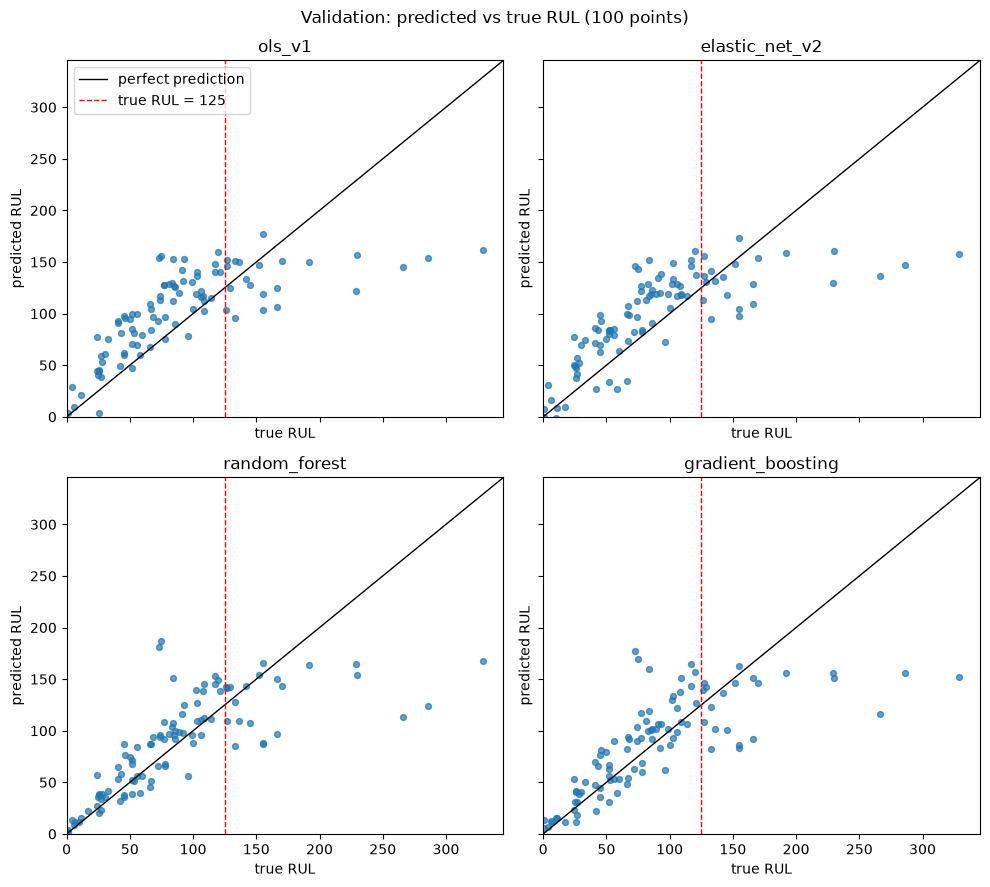

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9), sharex=True, sharey=True)
lim = max(val["rul"].max(), val[MODELS].to_numpy().max()) * 1.05
for ax, model in zip(axes.ravel(), MODELS):
    ax.scatter(val["rul"], val[model], s=18, alpha=0.7)
    ax.plot([0, lim], [0, lim], color="black", lw=1, label="perfect prediction")
    ax.axvline(THRESHOLD, color="red", ls="--", lw=1, label=f"true RUL = {THRESHOLD}")
    ax.set_title(model)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("true RUL")
    ax.set_ylabel("predicted RUL")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Validation: predicted vs true RUL (100 points)")
fig.tight_layout()
fig.savefig("../results/the_gap.png", dpi=150)
plt.show()

## 5. Where the models stop

In [6]:
far = val[val["rul"] > 200]
print(f"validation points with true RUL > 200: {len(far)}")
print(f"mean true RUL: {far['rul'].mean():.1f}")
print("mean prediction on those points:")
for model in MODELS:
    print(f"  {model:18s} {far[model].mean():.1f}")
print("largest validation prediction:")
for model in MODELS:
    print(f"  {model:18s} {val[model].max():.1f}")

validation points with true RUL > 200: 5
mean true RUL: 268.0
mean prediction on those points:
  ols_v1             147.7
  elastic_net_v2     146.2
  random_forest      144.7
  gradient_boosting  146.4
largest validation prediction:
  ols_v1             177.1
  elastic_net_v2     173.6
  random_forest      187.2
  gradient_boosting  177.5


## 6. Findings

- **Best model:** on validation, Random Forest has the lowest MAE (25.03) and the lowest late MAE (18.17); its RMSE (40.17) ties with Gradient Boosting. On test, Gradient Boosting is best (MAE 18.54, RMSE 25.33), with Random Forest close behind (18.95 / 25.88). Both tree models beat OLS and Elastic Net on both sets.
- **Early vs late error:** on validation every model is far worse on the 22 early points (MAE 46.31–50.92, RMSE 64.87–69.59) than on the 78 late points (MAE 18.17–28.79). The tree models are better on late points but not on early ones (early MAE 49.33 and 50.92 vs 47.31 and 46.31 for the linear models).
- **Over-prediction near failure:** on validation, 69–88% of late points get a prediction above the true RUL (OLS 88.46%, Elastic Net 85.90%, Random Forest 73.08%, Gradient Boosting 69.23%). On test it is 67–88%. Every model leans towards saying there is more life left than there is.
- **Validation vs test:** test error is lower for every model (for example Random Forest MAE 18.95 vs 25.03). Test has only 11 early points against 22 on validation, so its error is dominated by late points (89 of 100). The 11 test early-point numbers are based on few points.
- **The gap:** for the 5 validation points with true RUL above 200 (mean 268.0), every model predicts about 145–148 on average, and no model's largest validation prediction goes above 187.2. The fixed 10-cycle features cannot tell "200 left" from "300 left". This is the reason for the Phase 2 LSTM.
